# Willett et al. 2021, Handwriting BCI: Source Data Exploration

Reading and exploring the **raw Dryad source `.mat` files** for the handwriting brain-to-text dataset (subject T5, two 96-channel Utah arrays, 192 channels, 10 ms / 100 Hz binned threshold-crossing counts).

- Paper: Willett et al. (2021), *Nature* 593, 249-254, doi:10.1038/s41586-021-03506-2
- Dryad: doi:10.5061/dryad.wh70rxwmv
- Code: https://github.com/fwillett/handwritingBCI

This notebook uses the helpers in `utils.py`, reading the study folder that `download()` fills.

In [1]:
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from neuralshed.datasets.utils import dataset_dir
from neuralshed.datasets.willet_2021 import utils
from neuralshed.datasets.willet_2021.study import Willett2021Handwriting

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

# reads ./.env into os.environ
load_dotenv()

s = Willett2021Handwriting(path=dataset_dir("willet_2021") / "data")
s.download()

# the extracted deposit under the study folder
root = s.path / "handwritingBCIData"
sessions = utils.list_sessions(root)
print("data dir:", s.path)
print(len(sessions), "sessions:", sessions)

# a real-time decoding pilot day with both task files
SESSION = "t5.2019.11.25"


def trial_timing(path, task):
    """Delay and go-period lengths (s) of every trial of one task file."""
    data = utils.load_trial_variables(path, task)
    rows = []
    if task == "sentences":
        for tr in utils.extract_sentence_trials(data):
            rows.append(
                {
                    "family": task,
                    "condition": tr["sentence_condition"],
                    "delay_s": (tr["go_onset_bin"] - tr["delay_onset_bin"]) * utils.BIN_SIZE_S,
                    "go_s": tr["num_time_bins"] * utils.BIN_SIZE_S,
                }
            )
        return rows
    trials = utils.extract_single_letter_trials(data)
    for k, tr in enumerate(trials):
        nxt = trials[k + 1] if k + 1 < len(trials) else None
        same_block = nxt is not None and nxt["block_num"] == tr["block_num"]
        rows.append(
            {
                "family": "rest" if tr["cue"] == utils.REST_CUE else task,
                "condition": "pilot" if path.parent.name == "t5.2019.05.08" else "",
                "delay_s": (tr["go_onset_bin"] - tr["delay_onset_bin"]) * utils.BIN_SIZE_S,
                "go_s": (nxt["delay_onset_bin"] - tr["go_onset_bin"]) * utils.BIN_SIZE_S
                if same_block
                else np.nan,
            }
        )
    return rows

2026-10-13 16:30:14 - INFO - neuralset.events.study:463 - Success: Study downloaded to /Volumes/seagate_0/tether/datasets/willet_2021/data/Willett2021Handwriting.


2026-10-13 16:30:20 - INFO - neuralset.events.study:85 - Permissions set for /Volumes/seagate_0/tether/datasets/willet_2021/data/Willett2021Handwriting (skipped 0 non-owned items).


data dir: /Volumes/seagate_0/tether/datasets/willet_2021/data/Willett2021Handwriting
11 sessions: ['t5.2019.05.08', 't5.2019.06.03', 't5.2019.11.25', 't5.2019.12.09', 't5.2019.12.11', 't5.2019.12.18', 't5.2019.12.20', 't5.2020.01.06', 't5.2020.01.08', 't5.2020.01.13', 't5.2020.01.15']


## Session summary table

One row per session with its post-implant day, task files, time-series lengths and trial counts.

In [2]:
summary = pd.DataFrame(utils.session_summary(root))
summary

,session,description,post_implant_day,tasks,sentences_n_timesteps,sentences_n_trials,singleLetters_n_timesteps,singleLetters_n_trials,straightLines_n_timesteps,straightLines_n_trials
0,t5.2019.05.08,Sentence and character writing pilot day (no real-time decoding),994,"[sentences, singleLetters]",599319.0,102.0,336932.0,864.0,NaN,NaN
1,t5.2019.06.03,Attempted handwriting of straight lines,1020,[straightLines],NaN,NaN,NaN,NaN,359173.0,1152.0
2,t5.2019.11.25,Real-time decoding pilot day,1195,"[sentences, singleLetters]",536938.0,84.0,108471.0,310.0,NaN,NaN
3,t5.2019.12.09,Real-time decoding pilot day,1209,"[sentences, singleLetters]",553692.0,84.0,99992.0,310.0,NaN,NaN
4,t5.2019.12.11,Copy-typing evaluation,1211,"[sentences, singleLetters]",495342.0,84.0,95901.0,310.0,NaN,NaN
5,t5.2019.12.18,Copy-typing evaluation,1218,"[sentences, singleLetters]",457323.0,84.0,102663.0,310.0,NaN,NaN
6,t5.2019.12.20,Copy-typing evaluation,1220,"[sentences, singleLetters]",430830.0,84.0,104284.0,310.0,NaN,NaN
7,t5.2020.01.06,Copy-typing evaluation,1237,"[sentences, singleLetters]",380084.0,84.0,100379.0,310.0,NaN,NaN
8,t5.2020.01.08,Copy-typing evaluation,1239,"[sentences, singleLetters]",395357.0,84.0,97576.0,310.0,NaN,NaN
9,t5.2020.01.13,Free-answer evaluation,1244,"[sentences, singleLetters]",395539.0,155.0,99024.0,310.0,NaN,NaN


## Single-character writing: `singleLetters.mat`

Instructed-delay paradigm: a character cue appears during a delay period, then a go cue instructs T5 to attempt to write the character (1 s go period). Per-trial neural data is also packaged into `neuralActivityCube_{char}` tensors of shape `(reps, 201, 192)`, aligned so bin 50 (0-indexed) is the go cue.

In [3]:
sl = utils.load_single_letters(SESSION, root)
neural = sl["neuralActivityTimeSeries"]
print("neuralActivityTimeSeries:", neural.shape, neural.dtype)
print("n character conditions:", len(utils.list_cube_keys(sl)))
print("example cube 'a' shape:", utils.get_condition_cube(sl, "a").shape)

trials = utils.extract_single_letter_trials(sl)
print("n trials:", len(trials))
pd.DataFrame(trials).head(8)

neuralActivityTimeSeries: (108471, 192) uint8
n character conditions: 31
example cube 'a' shape: (10, 201, 192)
n trials: 310


,delay_onset_bin,go_onset_bin,cue,block_num
0,7670,7847,tilde,10
1,7947,8152,comma,10
2,8252,8469,questionMark,10
3,8569,8757,v,10
4,8857,9046,q,10
5,9146,9339,c,10
6,9439,9627,b,10
7,9727,9880,i,10


### Trial-averaged neural activity (heatmap) for a few characters

Mean over repetitions of each character's `(reps, 201, 192)` cube → `(201, 192)`. Bin 50 is the go cue.

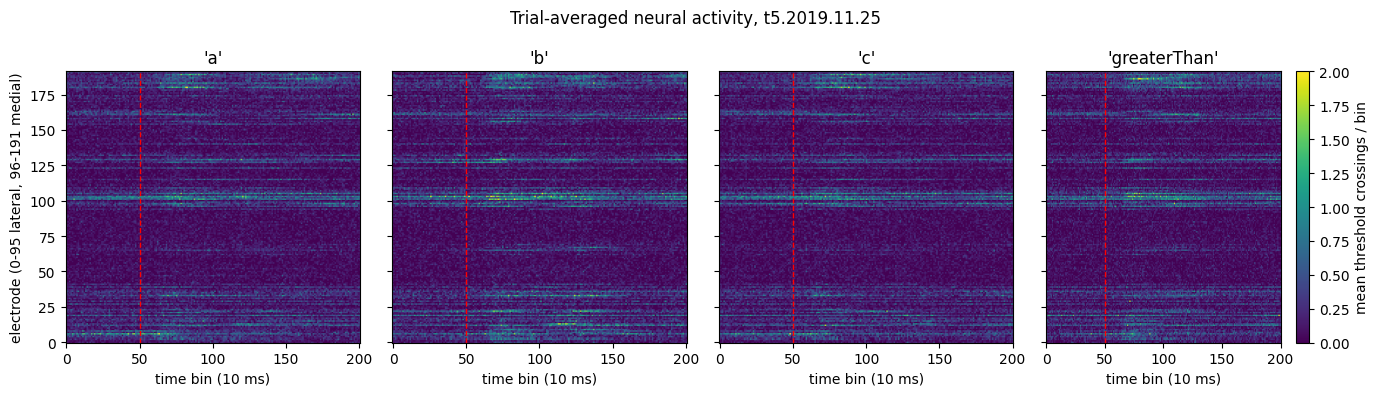

In [4]:
# 'greaterThan' is space
chars = ["a", "b", "c", "greaterThan"]

fig, axes = plt.subplots(1, len(chars), figsize=(14, 4), sharey=True)
for ax, ch in zip(axes, chars):
    # (reps, 201, 192) -> (192 channels, 201 bins)
    cube = utils.get_condition_cube(sl, ch)
    mean_act = cube.mean(axis=0).T
    im = ax.imshow(mean_act, aspect="auto", cmap="viridis", origin="lower")
    ax.axvline(utils.CUBE_GO_BIN, color="r", ls="--", lw=1)
    ax.set_title(f"'{ch}'")
    ax.set_xlabel("time bin (10 ms)")
axes[0].set_ylabel("electrode (0-95 lateral, 96-191 medial)")
fig.colorbar(im, ax=axes[-1], label="mean threshold crossings / bin")
fig.suptitle(f"Trial-averaged neural activity, {SESSION}")
plt.tight_layout()
plt.show()

### Single-trial raster of binned counts

First repetition of character 'a': the population of 192 electrodes over the 201-bin trial window.

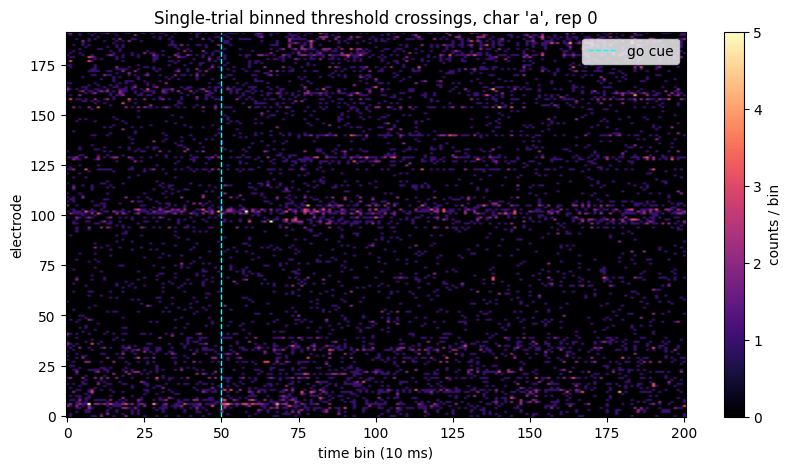

In [5]:
cube_a = utils.get_condition_cube(sl, "a")
# (192, 201)
trial0 = cube_a[0].T

fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(trial0, aspect="auto", cmap="magma", origin="lower")
ax.axvline(utils.CUBE_GO_BIN, color="cyan", ls="--", lw=1, label="go cue")
ax.set_xlabel("time bin (10 ms)")
ax.set_ylabel("electrode")
ax.set_title("Single-trial binned threshold crossings, char 'a', rep 0")
ax.legend(loc="upper right")
fig.colorbar(im, ax=ax, label="counts / bin")
plt.show()

## Sentence writing: `sentences.mat`

Instructed-delay paradigm with a 1-9 s delay, 5 s in most conditions. T5 attempts to write a full sentence, then turns his head right to end the trial. Conditions include open-loop (`OL`) copying and closed-loop (`CL`) real-time decoding. Sentence text uses `>` for space and `~` for period.

In [6]:
se = utils.load_sentences(SESSION, root)
print("neuralActivityTimeSeries:", se["neuralActivityTimeSeries"].shape)
print("neuralActivityCube:", se["neuralActivityCube"].shape)
print("conditions:", sorted(set(se["sentenceCondition"])))

strials = utils.extract_sentence_trials(se)
df = pd.DataFrame(strials)
df[["block_num", "sentence_condition", "num_time_bins", "excluded", "sentence_prompt"]].head(8)

neuralActivityTimeSeries: (536938, 192)
neuralActivityCube: (84, 13877, 192)
conditions: ['CL Corpus', 'CL Pandarinath', 'OL Copy']


,block_num,sentence_condition,num_time_bins,excluded,sentence_prompt
0,8,OL Copy,4432,False,the>sharp>edge>to>her>voice>reached>him~
1,8,OL Copy,4459,False,i'd>thought>you>know>it's>wider>than>that~
2,8,OL Copy,9896,False,it's>hard>to>see>how>they>could>ever>get>to>know>each>other>long>enough>for>...
3,8,OL Copy,8816,False,the>grieving>widow>was>rich>and>powerful>enough>to>hound>anyone>through>the>...
4,8,OL Copy,4062,False,i>bought>her>chocolate>for>her>last>week~
5,8,OL Copy,6258,False,then>it>wobbled>under>her>weight>and>tilted>forwards~
6,8,OL Copy,6476,False,"yet,>there>were>five>separate>master>keys>to>each>suite~"
7,8,OL Copy,4688,False,i>changed>my>mind>at>the>last>minute~


### Sentence duration by condition

Using `num_time_bins` (× 10 ms) per sentence, excluding flagged trials.

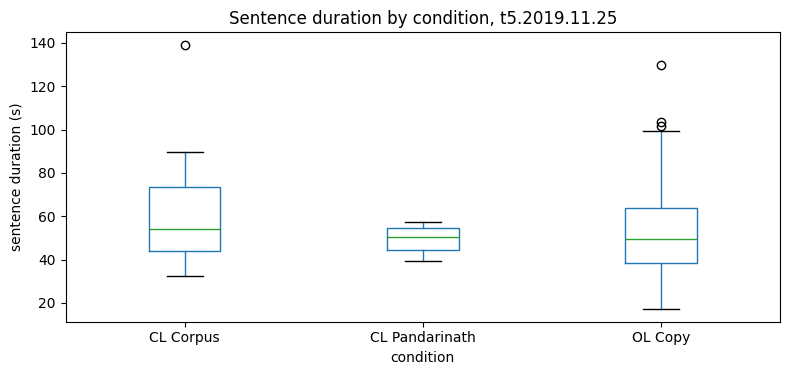

In [7]:
df_ok = df[~df["excluded"]].copy()
df_ok["duration_s"] = df_ok["num_time_bins"] * utils.BIN_SIZE_S

ax = df_ok.boxplot(column="duration_s", by="sentence_condition", figsize=(8, 4), grid=False)
ax.set_ylabel("sentence duration (s)")
ax.set_xlabel("condition")
plt.suptitle("")
plt.title(f"Sentence duration by condition, {SESSION}")
plt.tight_layout()
plt.show()

### Population neural activity during one sentence

Mean threshold-crossing count across all 192 electrodes over the active portion of one sentence trial.

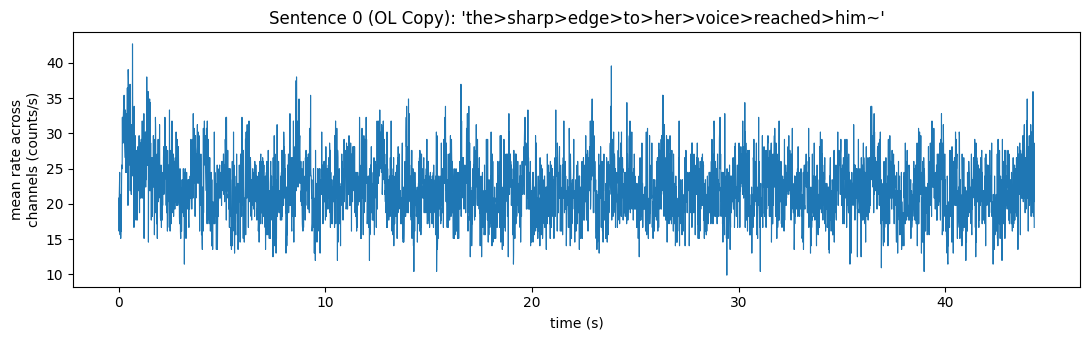

In [8]:
i = 0
n_bins = strials[i]["num_time_bins"]
# (n_bins, 192)
sent_cube = se["neuralActivityCube"][i, :n_bins, :]
# mean counts/s across channels
pop_rate = sent_cube.mean(axis=1) / utils.BIN_SIZE_S
t = np.arange(n_bins) * utils.BIN_SIZE_S

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(t, pop_rate, lw=0.8)
ax.set_xlabel("time (s)")
ax.set_ylabel("mean rate across\nchannels (counts/s)")
ax.set_title(f"Sentence 0 ({strials[i]['sentence_condition']}): '{strials[i]['sentence_prompt']}'")
plt.tight_layout()
plt.show()

## Blocks and clocks

Each task file splices its recording blocks end to end. `blockNumsTimeSeries` labels every bin with its block, and `clockTimeSeries` restarts at zero at the start of each block, because activity between blocks was not saved. The Study cuts each file at these seams, one timeline per block.

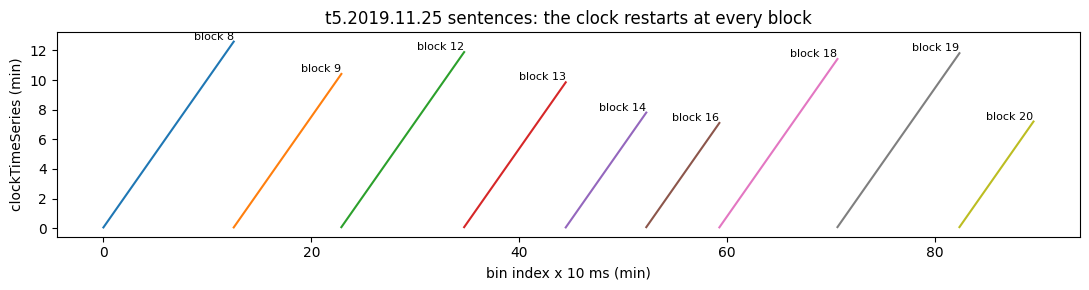

,blocks,seams,clock_restarts,hours
task,,,,
sentences,95,85,85,13.04
singleLetters,27,17,17,3.45
straightLines,8,7,7,1.00


In [9]:
path = utils.list_task_files(SESSION, root)["sentences"]
d = utils.load_variables(path, ["clockTimeSeries", "blockNumsTimeSeries", "blockList"])
block_nums = np.asarray(d["blockNumsTimeSeries"]).ravel()
clock_s = np.asarray(d["clockTimeSeries"]).ravel()
t = np.arange(len(block_nums)) * utils.BIN_SIZE_S

fig, ax = plt.subplots(figsize=(11, 3))
for block in np.atleast_1d(d["blockList"]):
    b0, b1 = utils.block_bins(block_nums, block)
    ax.plot(t[b0:b1] / 60, clock_s[b0:b1] / 60, lw=1.5)
    ax.text(t[b1 - 1] / 60, clock_s[b1 - 1] / 60, f"block {block}", fontsize=8, ha="right", va="bottom")
ax.set_xlabel("bin index x 10 ms (min)")
ax.set_ylabel("clockTimeSeries (min)")
ax.set_title(f"{SESSION} sentences: the clock restarts at every block")
plt.tight_layout()
plt.show()

rows = []
for session in sessions:
    for task, p in utils.list_task_files(session, root).items():
        d = utils.load_variables(p, ["clockTimeSeries", "blockNumsTimeSeries"])
        blocks = np.asarray(d["blockNumsTimeSeries"]).ravel()
        clock = np.asarray(d["clockTimeSeries"]).ravel()
        seams = np.flatnonzero(np.diff(blocks) != 0) + 1
        rows.append(
            {
                "task": task,
                "blocks": len(seams) + 1,
                "seams": len(seams),
                "clock_restarts": int((clock[seams] < clock[seams - 1]).sum()),
                "hours": len(blocks) * utils.BIN_SIZE_S / 3600,
            }
        )
blocks_df = pd.DataFrame(rows)
blocks_df.groupby("task").sum().round(2)

## Trial timing

The delay runs from the delay onset to the go cue. The go period runs from the go cue to the next trial's delay onset for characters and lines, and to the head turn for sentences. The Study's go rows follow these lengths.

In [10]:
rows = []
for session in sessions:
    for task, p in utils.list_task_files(session, root).items():
        rows += trial_timing(p, task)
timing = pd.DataFrame(rows)

timing.groupby(["family", "condition"]).agg(
    trials=("delay_s", "size"),
    delay_min=("delay_s", "min"),
    delay_median=("delay_s", "median"),
    delay_max=("delay_s", "max"),
    go_min=("go_s", "min"),
    go_median=("go_s", "median"),
    go_max=("go_s", "max"),
).round(2)

trials  delay_min  delay_median  delay_max  go_min  go_median  go_max
family        condition                                                                                 
rest          pilot                    27       1.82          2.36        2.9    1.01       1.01    1.02
sentences     CL Corpus               140       5.00          5.00        5.0   21.46      47.92  138.76
              CL Free Write            50       1.00          1.00        1.0   11.54      36.16   72.61
              CL Pandarinath           98       5.00          5.00        5.0   27.09      37.90   88.56
              OL Copy                 452       4.02          5.00        9.0    2.41      43.22  129.57
              OL Copy With Pauses      60       5.00          5.00        5.0    7.62      39.88   65.05
              OL Copy from Memory     200       6.00          6.00        6.0    3.23       9.45   24.08
singleLetters                        2790       1.50          1.98        2.5    1.00       1.00    1.01
              pilot                   837       1.50          2.40        3.0    1.01       1.01    1.02
straightLines                        1152       1.00          1.40        2.0    1.51       1.51    1.52

## Straight lines

`straightLines.mat` (2019.06.03) has the `singleLetters` layout, with 48 straight pen-stroke conditions `straightLine_{short,medium,long}_{1..16}` and 24 trials each. Angles are 22.5 degrees apart: condition 1 is rightward, 5 upward, 9 leftward. The Study gives each condition one `code`, 32-79, shown by distance and angle.

In [11]:
path = utils.list_task_files("t5.2019.06.03", root)["straightLines"]
lines = utils.load_trial_variables(path, "straightLines")
cues = pd.Series(np.atleast_1d(lines["movementCues"]).astype(str))
print("trials:", len(cues), "| conditions:", cues.nunique(), "| trials per condition:", sorted(set(cues.value_counts())))

conditions = pd.DataFrame({"cue": sorted(set(cues))})
conditions["distance"] = conditions.cue.str.split("_").str[1]
conditions["angle"] = conditions.cue.str.split("_").str[2].astype(int)
conditions["code"] = conditions.cue.map(utils.condition_code)
conditions.pivot(index="distance", columns="angle", values="code").loc[list(utils.LINE_DISTANCES)]

trials: 1152 | conditions: 48 | trials per condition: [24]


angle,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16
distance,,,,,,,,,,,,,,,,
short,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47
medium,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63
long,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79


## Array geometry

`arrayGeometryMap` is the same in all 21 files: the electrode number at each position of a 10 x 10 grid with 0.4 mm pitch, 0 where there is no electrode. Rows move toward the central sulcus and columns medially. The deposit gives one map for both arrays.

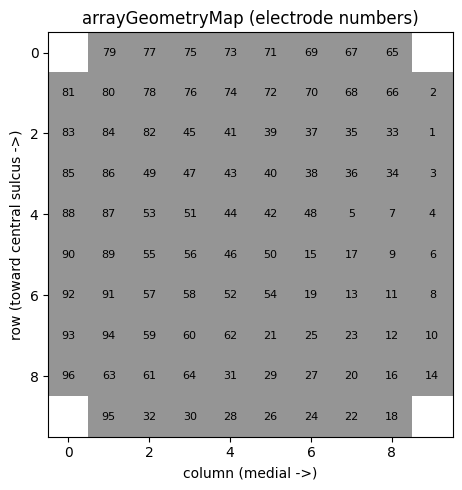

In [12]:
geometry = utils.ARRAY_GEOMETRY_MAP

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(geometry > 0, cmap="Greys", vmin=0, vmax=2)
for (r, c), number in np.ndenumerate(geometry):
    if number:
        ax.text(c, r, number, ha="center", va="center", fontsize=8)
ax.set_xlabel("column (medial ->)")
ax.set_ylabel("row (toward central sulcus ->)")
ax.set_title("arrayGeometryMap (electrode numbers)")
plt.tight_layout()
plt.show()

## Every sentence trial

One row per sentence across the 10 sentence files, with the published partitions. `trainTestPartitions_HeldOutBlocks.mat` holds out whole blocks, `trainTestPartitions_HeldOutTrials.mat` single trials inside blocks. Both index trials by their position in the session's sentence arrays.

In [13]:
partitions = {name: utils.load_partition(name, root) for name in utils.PARTITIONS}

rows = []
for session in sessions:
    path = utils.list_task_files(session, root).get("sentences")
    if path is None:
        continue
    data = utils.load_trial_variables(path, "sentences")
    for i, tr in enumerate(utils.extract_sentence_trials(data)):
        row = {
            "session": session,
            "trial": i,
            "condition": tr["sentence_condition"],
            "excluded": tr["excluded"],
            "prompt": tr["sentence_prompt"],
            "intended": tr["intended_text"],
        }
        for name, split in partitions.items():
            row[name] = split.get(session, {}).get(i, "")
        rows.append(row)
sentences = pd.DataFrame(rows)
print("sentences:", len(sentences), "| excluded:", int(sentences.excluded.sum()))
print("intended characters:", sentences.intended.str.len().sum())

for name in utils.PARTITIONS:
    display(pd.crosstab([sentences.condition, sentences.excluded], sentences[name].replace("", "(none)"), margins=True))

sentences: 1000 | excluded: 33
intended characters: 43501


HeldOutBlocks                 (none)  test  train   All
condition           excluded                           
CL Corpus           False          0   135      0   135
                    True           5     0      0     5
CL Free Write       False         48     0      0    48
                    True           2     0      0     2
CL Pandarinath      False          0    93      0    93
                    True           5     0      0     5
OL Copy             False          0     0    444   444
                    True           8     0      0     8
OL Copy With Pauses False          0     0     58    58
                    True           2     0      0     2
OL Copy from Memory False        189     0      0   189
                    True          11     0      0    11
All                              270   228    502  1000

HeldOutTrials                 (none)  test  train   All
condition           excluded                           
CL Corpus           False          0     7    128   135
                    True           5     0      0     5
CL Free Write       False         48     0      0    48
                    True           2     0      0     2
CL Pandarinath      False         93     0      0    93
                    True           5     0      0     5
OL Copy             False          0    50    394   444
                    True           8     0      0     8
OL Copy With Pauses False          0     6     52    58
                    True           2     0      0     2
OL Copy from Memory False        189     0      0   189
                    True          11     0      0    11
All                              363    63    574  1000

### Prompt against intended text

`intendedText` is the decoding target. It differs from `sentencePrompt` where the prompt carries `#` pause marks and where the prompt is a free-write question. One free-write trial has an empty `intendedText`: the readme's restaurant name whose spelling could not be determined. That trial is excluded.

In [14]:
differs = sentences[sentences.prompt != sentences.intended]
print("prompt != intended:", differs.condition.value_counts().to_dict())
display(differs.groupby("condition").head(2)[["session", "trial", "condition", "prompt", "intended"]])

empty = sentences[sentences.intended == ""]
empty[["session", "trial", "condition", "excluded", "prompt"]]

prompt != intended: {'CL Free Write': 50, 'OL Copy With Pauses': 40}


,session,trial,condition,prompt,intended
710,t5.2020.01.13,20,OL Copy With Pauses,"that>opin#ion>r#e#ally>#sh#ocked#>me,>c#oming>fr#om>my>own>#for#mer>tea#cher~","that>opinion>really>shocked>me,>coming>from>my>own>former>teacher~"
711,t5.2020.01.13,21,OL Copy With Pauses,he#>l#ean#ed>ou#t>#of>#t#he>cab>#win#dow~,he>leaned>out>of>the>cab>window~
820,t5.2020.01.13,130,CL Free Write,what types of cuisines do you like to eat?,i>like>mexican>food
821,t5.2020.01.13,131,CL Free Write,where were you born?,"rio>de>janerio,>brazil"


,session,trial,condition,excluded,prompt
987,t5.2020.01.15,142,CL Free Write,True,what is your favorite restaurant?


## Notes

- **Neural signal:** binned threshold-crossing counts (-3.5 x RMS threshold), 10 ms bins (100 Hz), `uint8`, 192 channels. Channels 0-95 = lateral array, 96-191 = medial array.
- **`neuralActivityTimeSeries`** `(T, 192)` splices a file's recording blocks, and `clockTimeSeries` restarts at every block. The per-trial **cubes** are convenience re-packagings derived from it.
- **singleLetters / straightLines** use `goPeriodOnsetTimeBin` / `delayPeriodOnsetTimeBin`, **sentences** use `goCueOnsetTimeBin` / `delayCueOnsetTimeBin`. Both are 1-based bin indices.
- **Delays** are 1.5-3.0 s for characters, 1.0-2.0 s for lines and 1.0-9.0 s for sentences, against the 2.0-3.0 s and 5 s the documentation gives. The line go period is 1.5 s.
- **Sentences:** 1,000 trials, 33 excluded by the authors. The published partitions leave the memory and free-write conditions unlabeled.